For our Fashion Product Intelligence V2, I would choose EfficientNetB0 over MobileNetV2.

Factor	MobileNetV2	EfficientNetB0
Accuracy potential	Good	Usually better
Model size	Smaller	Larger
Training speed	Faster	Slower
Computational requirement	Lower	Higher
Feature extraction	Good	Stronger
Fashion classification	Good	Better candidate
Recommendation embeddings	Good	Better candidate
Best for our project	⭐⭐⭐⭐	⭐⭐⭐⭐⭐
Why EfficientNetB0 for our project?

We aren't building a real-time mobile application. Our main goals are:

54-class fashion article classification
Extract strong visual features
Use those features for similarity-based recommendations

EfficientNetB0 is therefore a better fit because we can prioritize feature quality and classification performance over maximum speed.

Our pipeline becomes:

Women Fashion Dataset
17,750 images
        ↓
EfficientNetB0
ImageNet pretrained
        ↓
Fine-tuning
        ↓
54 Article Types
        ↓
Classification
        ↓
EfficientNet features
        ↓
Image Embeddings
        ↓
Cosine Similarity
        ↓
Similar Fashion Products
But one important point

We cannot honestly say EfficientNetB0 is better than MobileNetV2 based only on architecture names.

The strongest statement for your project is:

EfficientNetB0 was selected as the primary architecture because it offers a strong accuracy–efficiency trade-off and is well suited to extracting visual features for both classification and similarity-based recommendation.

If you actually want to prove MobileNetV2 vs EfficientNetB0, we'd need to train both under the same conditions and compare their test metrics.

In [1]:
import numpy as np 
import tensorflow as tf

2026-08-24 11:33:34.996063: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Why EfficientNetB0?

It is a good fit because:

Pretrained on ImageNet
Strong image feature extraction
More sophisticated than a small custom CNN
Good accuracy/efficiency trade-off
Can be reused as the feature extractor for our recommendation system
Avoids spending many hours training multiple architectures
What about the MobileNetV2 training currently running?

Since you're only partway through the first epoch and the training is taking roughly 2 seconds/step, I would stop the MobileNetV2 training now rather than spend the remaining time on it.

In [2]:
import os
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input

sns.set_theme(style="whitegrid")

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.16.2


In [3]:
# Load saved spilts

train_df = pd.read_csv("train_images_v2.csv")
val_df = pd.read_csv("val_images_v2.csv")
test_df = pd.read_csv("test_images_v2.csv")

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Training: (12425, 17)
Validation: (2662, 17)
Test: (2663, 17)


In [4]:
# Recreate label mapping

from sklearn.preprocessing import LabelEncoder

# Create label encoder
label_encoder = LabelEncoder()

# Fit only on training classes
label_encoder.fit(train_df["articleTypeName"])

# Encode labels
train_df["label"] = label_encoder.transform(
    train_df["articleTypeName"]
)

val_df["label"] = label_encoder.transform(
    val_df["articleTypeName"]
)

test_df["label"] = label_encoder.transform(
    test_df["articleTypeName"]
)

NUM_CLASSES = len(label_encoder.classes_)

print("Number of classes:", NUM_CLASSES)

# verify
print("Training classes:", train_df["label"].nunique())
print("Validation classes:", val_df["label"].nunique())
print("Test classes:", test_df["label"].nunique())

print("\nLabel mapping:")
for i, name in enumerate(label_encoder.classes_):
    print(i, "→", name)



Number of classes: 54
Training classes: 54
Validation classes: 54
Test classes: 54

Label mapping:
0 → Bangle
1 → Belts
2 → Bra
3 → Bracelet
4 → Briefs
5 → Capris
6 → Casual Shoes
7 → Clutches
8 → Deodorant
9 → Dresses
10 → Dupatta
11 → Earrings
12 → Face Moisturisers
13 → Flats
14 → Flip Flops
15 → Foundation and Primer
16 → Handbags
17 → Heels
18 → Highlighter and Blush
19 → Jackets
20 → Jeans
21 → Jewellery Set
22 → Kajal and Eyeliner
23 → Kurta Sets
24 → Kurtas
25 → Kurtis
26 → Leggings
27 → Lip Gloss
28 → Lipstick
29 → Nail Polish
30 → Necklace and Chains
31 → Night suits
32 → Nightdress
33 → Pendant
34 → Perfume and Body Mist
35 → Ring
36 → Sarees
37 → Scarves
38 → Shirts
39 → Shorts
40 → Skirts
41 → Socks
42 → Sports Shoes
43 → Stoles
44 → Sunglasses
45 → Sweaters
46 → Sweatshirts
47 → Tops
48 → Track Pants
49 → Trousers
50 → Tshirts
51 → Tunics
52 → Wallets
53 → Watches


Why fit only on training data?

This is important for proper machine-learning practice:

Training labels
 ↓
LabelEncoder.fit()
 ↓
54 class mapping
 ↓
Validation/Test
 ↓
LabelEncoder.transform()

 don't fit a separate encoder on validation or test data because that could create inconsistent label mappings.

In [5]:
# Image Classification
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
image_dir = "images"

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Image size: (224, 224)
Batch size: 32


In [6]:
# create image path ---> saved  images in image_dataset notebook

train_df["image_path"] = train_df["filename"].apply(
    lambda x: os.path.join(image_dir, x)
)

val_df["image_path"] = val_df["filename"].apply(
    lambda x: os.path.join(image_dir, x)
)

test_df["image_path"] = test_df["filename"].apply(
    lambda x: os.path.join(image_dir, x)
)

In [7]:
# Check image path

print(
    "Training image exists:",
    os.path.exists(train_df["image_path"].iloc[0])
)

print(
    "Validation image exists:",
    os.path.exists(val_df["image_path"].iloc[0])
)

print(
    "Test image exists:",
    os.path.exists(test_df["image_path"].iloc[0])
)

Training image exists: True
Validation image exists: True
Test image exists: True


In [8]:
# image loading

def load_image(image_path, label):

    image = tf.io.read_file(image_path)

    image = tf.image.decode_jpeg(
        image,
        channels=3
    )

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    image = tf.cast(
        image,
        tf.float32
    )

    return image, label

In [9]:
# Efficientnet preprocessing

def preprocess_efficientnet(image, label):

    image = preprocess_input(image)

    return image, label

In [10]:
# dataset creation--- tensorflow dataset creation
def create_dataset(dataframe, shuffle=False):

    dataset = tf.data.Dataset.from_tensor_slices(
        (
            dataframe["image_path"].values,
            dataframe["label"].values
        )
    )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.map(
        preprocess_efficientnet,
        num_parallel_calls=AUTOTUNE
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=1000,
            seed=42
        )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(
        AUTOTUNE
    )

    return dataset



# create datasets
train_ds = create_dataset(
    train_df,
    shuffle=True
)

val_ds = create_dataset(
    val_df,
    shuffle=False
)

test_ds = create_dataset(
    test_df,
    shuffle=False
)

print("TensorFlow datasets created successfully.")

TensorFlow datasets created successfully.


In [11]:
# verify preprocessing -->verify one batch, pixels will not be 0–1.
images, labels = next(iter(train_ds))

images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print(
    "Pixel minimum:",
    tf.reduce_min(images).numpy()
)

print(
    "Pixel maximum:",
    tf.reduce_max(images).numpy()
)

2026-08-24 13:08:47.291220: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:450] ShuffleDatasetV3:3: Filling up shuffle buffer (this may take a while): 568 of 1000
2026-08-24 13:08:55.221746: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:480] Shuffle buffer filled.
2026-08-24 13:09:05.949129: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:450] ShuffleDatasetV3:3: Filling up shuffle buffer (this may take a while): 695 of 1000
2026-08-24 13:09:10.040861: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:480] Shuffle buffer filled.


Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Pixel minimum: 0.0
Pixel maximum: 255.0


In [12]:
# Build model -->Load pretrained EfficientNetB0
base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

print("EfficientNetB0 loaded successfully.")
print("Number of base layers:", len(base_model.layers))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
EfficientNetB0 loaded successfully.
Number of base layers: 238


In [13]:
# Add Classification head
model = models.Sequential([
    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 54)             │        69,174 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,118,745 (15.71 MB)

 Trainable params: 69,174 (270.21 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Why GlobalAveragePooling2D?

Instead of flattening the entire feature map, it converts the learned convolutional features into a compact representation.
MobileNetV2
     ↓
Feature maps
     ↓
GlobalAveragePooling
     ↓
Dropout
     ↓
54-class Softmax

In [14]:
# Compile the model and model training
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("EfficientNetB0 model compiled successfully.")

# callbacks 
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "efficientnetb0_best.keras",
        monitor="val_accuracy",
        save_best_only=True
    )
]

# model training 
start_time = time.time()

history_initial = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

training_time = time.time() - start_time

print(
    "Initial training time:",
    round(training_time / 60, 2),
    "minutes"
)

EfficientNetB0 model compiled successfully.
Epoch 1/10


2026-08-24 13:10:26.873319: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:450] ShuffleDatasetV3:3: Filling up shuffle buffer (this may take a while): 474 of 1000
2026-08-24 13:10:34.804180: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:480] Shuffle buffer filled.


389/389 ━━━━━━━━━━━━━━━━━━━━ 1402s 3s/step - accuracy: 0.6913 - loss: 1.1008 - val_accuracy: 0.8047 - val_loss: 0.6148 - learning_rate: 0.0010
Epoch 2/10


2026-08-24 13:33:17.950361: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:450] ShuffleDatasetV3:3: Filling up shuffle buffer (this may take a while): 744 of 1000
2026-08-24 13:33:21.430659: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:480] Shuffle buffer filled.


389/389 ━━━━━━━━━━━━━━━━━━━━ 1474s 4s/step - accuracy: 0.8130 - loss: 0.5628 - val_accuracy: 0.8332 - val_loss: 0.5061 - learning_rate: 0.0010
Epoch 3/10


2026-08-24 13:57:52.177049: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:450] ShuffleDatasetV3:3: Filling up shuffle buffer (this may take a while): 521 of 1000
2026-08-24 13:58:01.143714: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:480] Shuffle buffer filled.


... (11 outputs left out)

2026-08-24 16:25:50.203522: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:450] ShuffleDatasetV3:3: Filling up shuffle buffer (this may take a while): 744 of 1000
2026-08-24 16:25:54.070896: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:480] Shuffle buffer filled.


389/389 ━━━━━━━━━━━━━━━━━━━━ 1130s 3s/step - accuracy: 0.8874 - loss: 0.3159 - val_accuracy: 0.8659 - val_loss: 0.3930 - learning_rate: 0.0010
Epoch 10/10


2026-08-24 16:44:39.743543: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:450] ShuffleDatasetV3:3: Filling up shuffle buffer (this may take a while): 880 of 1000
2026-08-24 16:44:40.995338: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:480] Shuffle buffer filled.


389/389 ━━━━━━━━━━━━━━━━━━━━ 1129s 3s/step - accuracy: 0.8918 - loss: 0.3051 - val_accuracy: 0.8595 - val_loss: 0.3914 - learning_rate: 0.0010
Initial training time: 233.56 minutes


Validation accuracy went from 80.47% → 86.59%.

2. There is some overfitting.

At Epoch 10:

Training accuracy = 89.18%
Validation accuracy = 85.95%

There is a ~3.2 percentage-point gap.

That's not alarming, but it tells us that the frozen ImageNet features plus classification head have reached a good point and fine-tuning could potentially improve the fashion-specific features.

3. Best validation accuracy

Your best recorded validation accuracy is:

86.59% at Epoch 9

And the lowest validation loss is:

0.3914 at Epoch 10





plot training curve

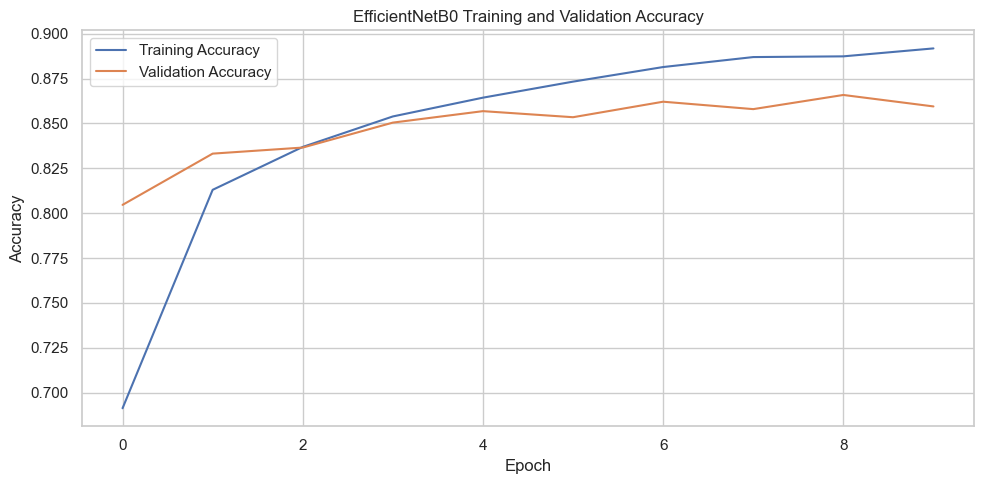

In [15]:
# Accuracy--train
plt.figure(figsize=(10, 5))

plt.plot(
    history_initial.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_initial.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("EfficientNetB0 Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()


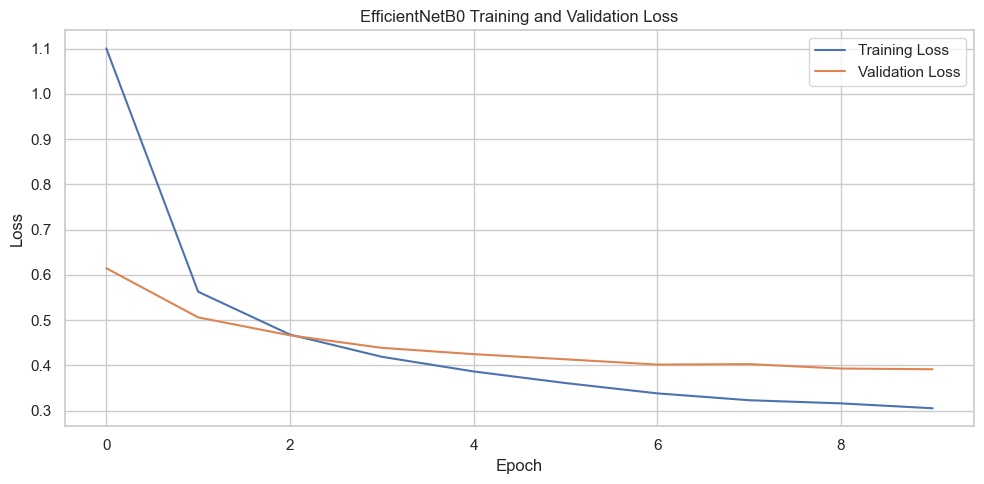

In [16]:
# validation loss
plt.figure(figsize=(10, 5))

plt.plot(
    history_initial.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_initial.history["val_loss"],
    label="Validation Loss"
)

plt.title("EfficientNetB0 Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Fine tuning

In [20]:
# Unfreeze upper layer
# Unfreeze EfficientNetB0 for fine-tuning

base_model.trainable = True

# Keep the lower layers frozen
fine_tune_at = 200

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

trainable_layers = sum(
    layer.trainable
    for layer in base_model.layers
)

print("Total layers:", len(base_model.layers))
print("Trainable layers:", trainable_layers)

Total layers: 238
Trainable layers: 38


238 total EfficientNetB0 layers
200 lower layers frozen
38 upper layers trainable

So fine-tuning only the upper part of EfficientNetB0 rather than changing the entire pretrained network.

EfficientNetB0 contains many pretrained layers:

EfficientNetB0
│
├── Lower layers → FROZEN
│   Generic visual features
│   edges, shapes, textures
│
└── Upper layers → TRAINABLE
    Fashion-specific features
    article shapes, patterns, details

This keeps the earlier generic ImageNet features frozen while allowing the later layers to adapt to Women fashion article types.

In [22]:
# Recompile with a very small learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("EfficientNetB0 fine-tuning model compiled successfully.")

EfficientNetB0 fine-tuning model compiled successfully.


1e-5

Because the pretrained weights are already useful. We want small adjustments, not large changes that could destroy the learned ImageNet features.

In [ ]:
# Fine tune------->tc
start_time = time.time()

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3,
    callbacks=callbacks
)

fine_tuning_time = time.time() - start_time

print(
    "Fine-tuning time:",
    round(fine_tuning_time / 60, 2),
    "minutes"
)

Epoch 1/3


2026-08-24 17:25:34.005815: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:450] ShuffleDatasetV3:3: Filling up shuffle buffer (this may take a while): 384 of 1000
2026-08-24 17:25:45.932101: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:480] Shuffle buffer filled.


389/389 ━━━━━━━━━━━━━━━━━━━━ 1845s 5s/step - accuracy: 0.8386 - loss: 0.5484 - val_accuracy: 0.8366 - val_loss: 0.4840 - learning_rate: 1.0000e-05
Epoch 2/3


2026-08-24 17:55:56.232416: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:450] ShuffleDatasetV3:3: Filling up shuffle buffer (this may take a while): 752 of 1000
2026-08-24 17:56:00.251932: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:480] Shuffle buffer filled.


389/389 ━━━━━━━━━━━━━━━━━━━━ 1766s 4s/step - accuracy: 0.8625 - loss: 0.4206 - val_accuracy: 0.8437 - val_loss: 0.4526 - learning_rate: 1.0000e-05
Epoch 3/3


2026-08-24 18:24:56.210559: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:450] ShuffleDatasetV3:3: Filling up shuffle buffer (this may take a while): 674 of 1000
2026-08-24 18:25:01.065862: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:480] Shuffle buffer filled.


389/389 ━━━━━━━━━━━━━━━━━━━━ 1761s 4s/step - accuracy: 0.8737 - loss: 0.3834 - val_accuracy: 0.8467 - val_loss: 0.4482 - learning_rate: 2.0000e-06
Fine-tuning time: 89.58 minutes


Initial:
val_loss = 0.3930

Fine-tuning:
val_loss = 0.4482

In [ ]:

# Restore the best EfficientNetB0 model from initial training--->

best_model = tf.keras.models.load_model(
    "efficientnetb0_best.keras"
)

print("Best EfficientNetB0 model loaded successfully.")

Best EfficientNetB0 model loaded successfully.


In [29]:
print(best_model.name)
print("Model restored successfully.")

sequential
Model restored successfully.


In [30]:
monitor="val_accuracy"
save_best_only=True

In [31]:
# Evaluate the saved model---->tc
test_loss, test_accuracy = best_model.evaluate(
    test_ds,
    verbose=1
)

print("\nFinal Test Loss:", round(test_loss, 4))
print("Final Test Accuracy:", round(test_accuracy, 4))
print(
    "Final Test Accuracy (%):",
    round(test_accuracy * 100, 2),
    "%"
)

84/84 ━━━━━━━━━━━━━━━━━━━━ 335s 4s/step - accuracy: 0.8592 - loss: 0.3806

Final Test Loss: 0.3806
Final Test Accuracy: 0.8592
Final Test Accuracy (%): 85.92 %


Final EfficientNetB0 classification result
Metric	Result
Training accuracy — final epoch	89.18%
Best validation accuracy	86.59%
Test accuracy	85.92%
Test loss	0.3806
Classes	54
Test images	2,663


In [ ]:
# prediction--classification report--
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = best_model.predict(
        images,
        verbose=0
    )

    y_true.extend(labels.numpy())
    y_pred.extend(
        np.argmax(predictions, axis=1)
    )

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Predictions generated successfully.")
print("True labels:", len(y_true))
print("Predicted labels:", len(y_pred))

Predictions generated successfully.
True labels: 2663
Predicted labels: 2663


2026-08-24 19:19:37.512694: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [33]:
# Classification Report
from sklearn.metrics import classification_report

class_names = label_encoder.classes_

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
)

print(report)


                       precision    recall  f1-score   support

               Bangle     1.0000    0.7000    0.8235        10
                Belts     0.9756    1.0000    0.9877        40
                  Bra     0.9861    0.9861    0.9861        72
             Bracelet     0.8333    0.7143    0.7692         7
               Briefs     0.9762    0.9535    0.9647        43
               Capris     0.7500    0.9474    0.8372        19
         Casual Shoes     0.7021    0.6600    0.6804        50
             Clutches     0.8500    0.7727    0.8095        44
            Deodorant     1.0000    0.9474    0.9730        19
              Dresses     0.8627    0.7458    0.8000        59
              Dupatta     0.7500    0.5294    0.6207        17
             Earrings     0.9692    1.0000    0.9844        63
    Face Moisturisers     1.0000    1.0000    1.0000         9
                Flats     0.5517    0.2133    0.3077        75
           Flip Flops     0.9630    0.7027    0.8125  

Overall performance
Metric	Score
Test Accuracy	85.92%
Macro Precision	86.37%
Macro Recall	82.01%
Macro F1	83.16%
Weighted Precision	85.47%
Weighted Recall	85.92%
Weighted F1	84.96%
Test samples	2,663
Classes	54
How to interpret this

85.92% accuracy means the model correctly classified approximately 86 out of every 100 unseen product images.

The macro F1 of 83.16% is particularly useful because it treats all 54 article types equally. It's lower than the overall accuracy because some smaller/difficult classes perform considerably worse.

Strong-performing classes

Some categories are classified extremely well:

Belts: F1 = 98.77%
Bra: F1 = 98.61%
Earrings: F1 = 98.44%
Handbags: F1 = 97.48%
Briefs: F1 = 96.47%
Deodorant: F1 = 97.30%
Foundation and Primer: F1 = 95.24%

These categories likely have distinctive visual characteristics.

Classes that need attention

A few categories have substantially lower recall/F1:

Article Type	Precision	Recall	F1
Flats	55.17%	21.33%	30.77%
Jackets	66.67%	25.00%	36.36%
Dupatta	75.00%	52.94%	62.07%
Casual Shoes	70.21%	66.00%	68.04%
Bracelet	83.33%	71.43%	76.92%
Dresses	86.27%	74.58%	80.00%

However, notice that Jackets has only 8 test images and Flats has 75, so the low Jacket score is based on a very small sample, while the Flats result is much more meaningful.

Most important finding: Flats

The Flats class deserves attention.

Precision = 55.17%
Recall    = 21.33%
F1        = 30.77%
Support   = 75

A recall of 21.33% means the model is missing many actual Flats and predicting them as other visually similar categories.

This is exactly the type of problem the confusion matrix can reveal.

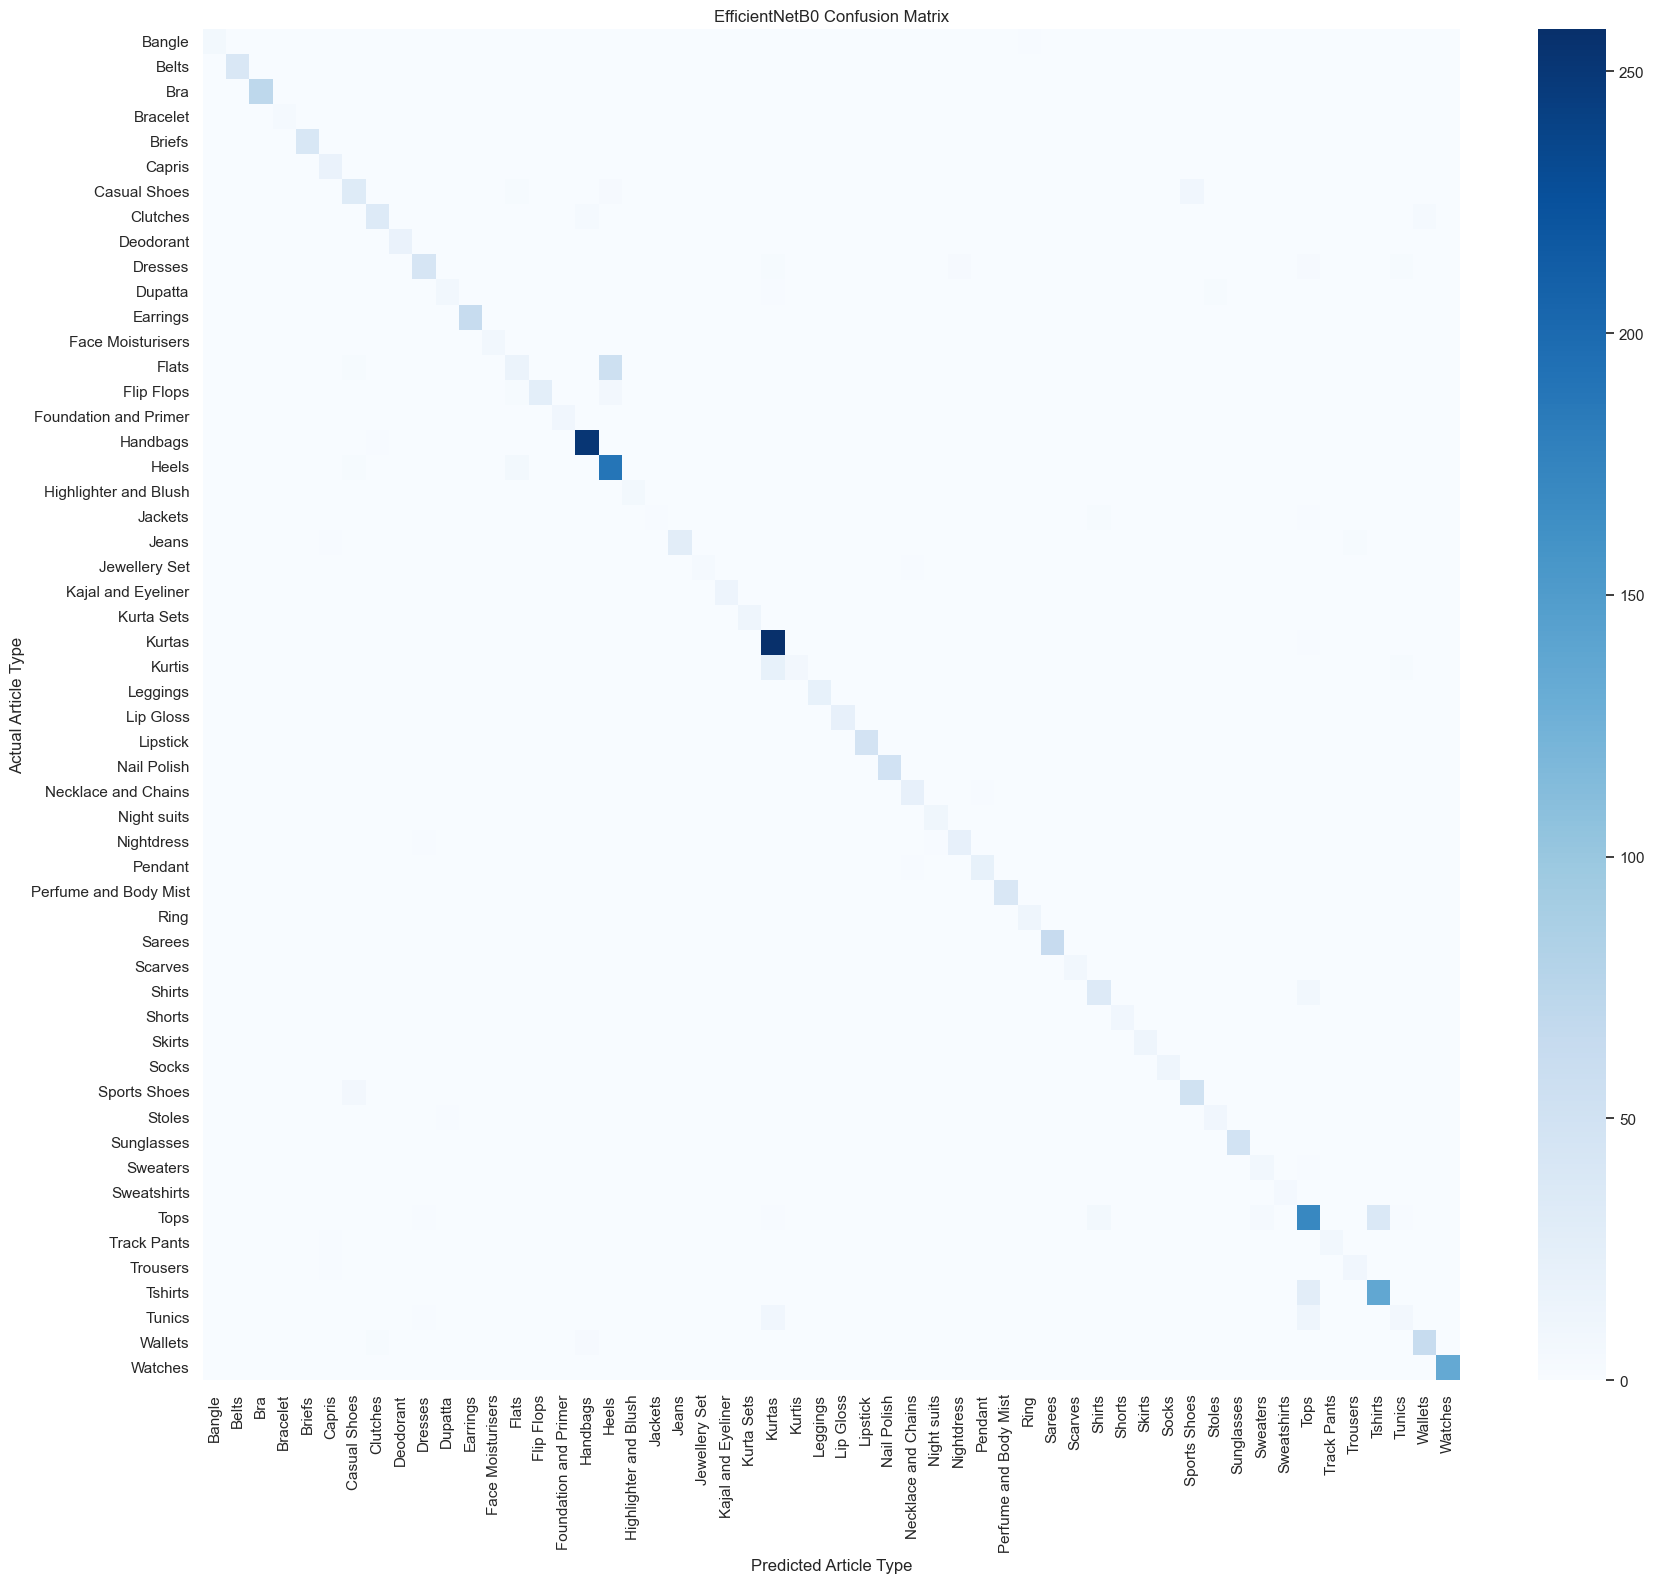

In [34]:
# Confusiom matrix
cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(18, 16))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("EfficientNetB0 Confusion Matrix")
plt.xlabel("Predicted Article Type")
plt.ylabel("Actual Article Type")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [35]:
cm_no_diag = cm.copy()

np.fill_diagonal(cm_no_diag, 0)

misclassifications = []

for actual_idx in range(len(class_names)):
    for predicted_idx in range(len(class_names)):

        count = cm_no_diag[
            actual_idx,
            predicted_idx
        ]

        if count > 0:
            misclassifications.append({
                "Actual": class_names[actual_idx],
                "Predicted": class_names[predicted_idx],
                "Count": count
            })

misclassifications_df = pd.DataFrame(
    misclassifications
).sort_values(
    "Count",
    ascending=False
)

display(
    misclassifications_df.head(20)
)

,Actual,Predicted,Count
26,Flats,Heels,55
90,Tops,Tshirts,38
100,Tshirts,Tops,28
48,Kurtis,Kurtas,21
105,Tunics,Tops,12
10,Casual Shoes,Sports Shoes,10
102,Tunics,Kurtas,10
69,Shirts,Tops,9
28,Flip Flops,Heels,8
73,Sports Shoes,Casual Shoes,8


In [37]:
import os

print(
    "Model file exists:",
    os.path.exists("efficientnetb0_best.keras")
)

Model file exists: True


In [38]:
best_model = tf.keras.models.load_model(
    "efficientnetb0_best.keras"
)

print("Best EfficientNetB0 model loaded successfully.")

Best EfficientNetB0 model loaded successfully.
